# Empirical carrier mobility

Prerequisite: [Empirical carrier mobility and relaxation-time trajectories](../../../docs/lecture-notes/solidstate/semiconductors/carrier-mobility/index.md).

## Learning objectives

- evaluate lattice and ionized-impurity mobility contributions;
- combine them with Matthiessen's rule;
- verify mobility–relaxation-time conversion; and
- inspect one seeded relaxation-time trajectory.

Run the cells from top to bottom. Mobility is reported in $\mathrm{cm^2/(V\,s)}$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from projectkoios.physkit.constants import SI
from projectkoios.physkit.solidstate.semiconductors.mobility import (
    CarrierMobilityModel,
    SemiconductorMobilityModel,
    simulate_electron_trajectory,
)

In [2]:
electron = CarrierMobilityModel(
    effective_mass=0.26 * SI.me0,
    lattice_mobility_reference=1500.0,
    impurity_mobility_reference=1500.0,
    impurity_concentration_reference=1.0e16,
)
hole = CarrierMobilityModel(
    effective_mass=0.39 * SI.me0,
    lattice_mobility_reference=450.0,
    impurity_mobility_reference=450.0,
    impurity_concentration_reference=1.0e16,
)
silicon_mobility = SemiconductorMobilityModel(electron=electron, hole=hole)

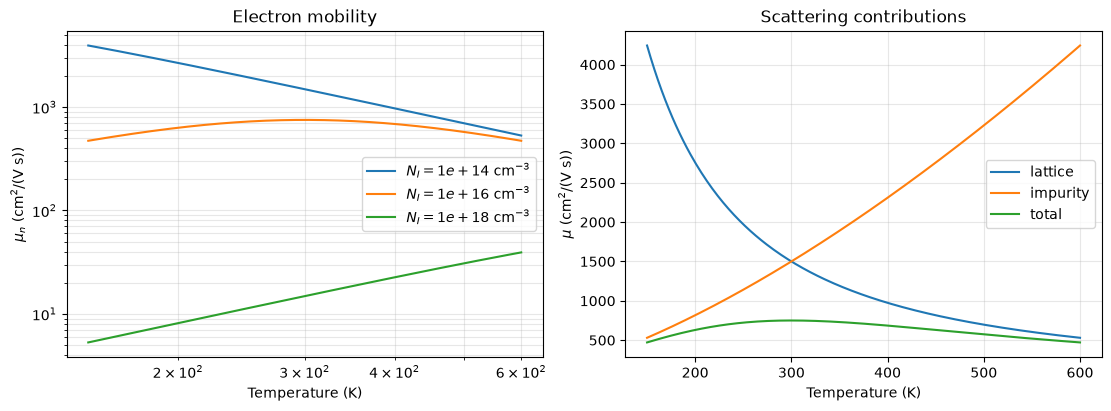

In [3]:
temperature = np.linspace(150.0, 600.0, 240)
impurity_concentrations = (1.0e14, 1.0e16, 1.0e18)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for concentration in impurity_concentrations:
    axes[0].loglog(
        temperature,
        silicon_mobility.electron.total_mobility(temperature, concentration),
        label=rf"$N_I={concentration:.0e}\ \mathrm{{cm^{{-3}}}}$",
    )
axes[0].set(title="Electron mobility", xlabel="Temperature (K)", ylabel=r"$\mu_n$ (cm$^2$/(V s))")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend()

reference_concentration = 1.0e16
axes[1].plot(temperature, electron.lattice_mobility(temperature), label="lattice")
axes[1].plot(temperature, electron.impurity_mobility(temperature, reference_concentration), label="impurity")
axes[1].plot(temperature, electron.total_mobility(temperature, reference_concentration), label="total")
axes[1].set(title="Scattering contributions", xlabel="Temperature (K)", ylabel=r"$\mu$ (cm$^2$/(V s))")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.show()

In [4]:
electron_reference = float(electron.total_mobility(300.0, 1.0e16))
hole_reference = float(hole.total_mobility(300.0, 1.0e16))
relaxation_time = electron.relaxation_time(electron_reference)
reconstructed = electron.mobility_from_relaxation_time(relaxation_time)

np.testing.assert_allclose(electron_reference, 750.0)
np.testing.assert_allclose(hole_reference, 225.0)
np.testing.assert_allclose(reconstructed, electron_reference)
print(f"electron mobility at reference conditions: {electron_reference:.1f} cm^2/(V s)")
print(f"hole mobility at reference conditions: {hole_reference:.1f} cm^2/(V s)")
print(f"electron relaxation time: {float(relaxation_time):.3e} s")

electron mobility at reference conditions: 750.0 cm^2/(V s)
hole mobility at reference conditions: 225.0 cm^2/(V s)
electron relaxation time: 1.109e-13 s


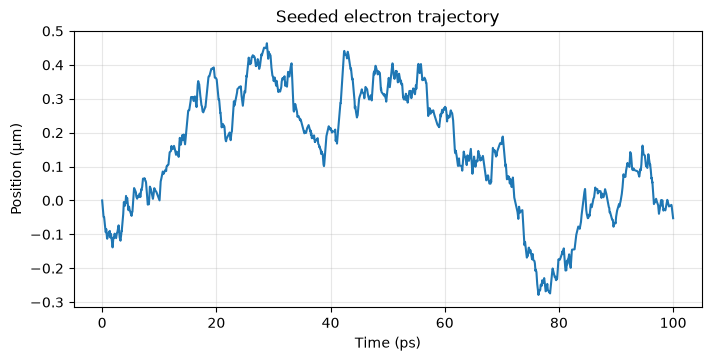

In [5]:
trajectory = simulate_electron_trajectory(
    model=electron,
    temperature=300.0,
    impurity_concentration=1.0e16,
    electric_field=1.0e3,
    time_step=1.0e-14,
    step_count=10_000,
    seed=1_234,
)
assert np.all(np.isfinite(trajectory.position))

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.plot(trajectory.time * 1.0e12, trajectory.position * 1.0e6)
ax.set(xlabel="Time (ps)", ylabel="Position (µm)", title="Seeded electron trajectory")
ax.grid(True, alpha=0.3)
plt.show()

## Questions

1. At what temperature do the two scattering contributions become equal for each impurity density?
2. How does changing the impurity exponent alter the crossover?
3. Which trajectory features change with the random seed, and which aggregate quantities should not?
4. Why is this model insufficient for high-field velocity saturation?